# Week 1: Data profiling, relationships and KPI groundwork
**CadetX warehouse analytics, team project**

Run top to bottom (Runtime → Run all). Folder layout the notebook expects:

```
data/raw/        the 12 source CSVs, unchanged (upload them here)
data/cleaned/    written by this notebook (regenerated, not committed to GitHub)
docs/            validation log, cleaning log, relationship checks, data dictionary
```

**Week 1 deliverables and where they live**
- Profiling of all 12 tables: section 3
- Table relationships and join keys: section 5
- Table-specific checks and reconciliation: section 6
- Cleaning and validation log: section 9
- KPIs and analysis questions: section 8
- Data dictionary draft: section 10

Sprint notes, the README and the ER diagram are separate files in `/week-01`.

Business rules that drive the numbers are set once in section 1. Confirm each one against *Fields Documentation.docx* before you submit.

## 1. Setup and configuration

In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RAW = Path("data/raw")
CLEAN = Path("data/cleaned")
DOCS = Path("docs")
for folder in (CLEAN, DOCS):
    folder.mkdir(parents=True, exist_ok=True)

# Business rules (confirm against the Fields Documentation)
EXCLUDED_ORDER_STATUSES = {"Cancelled", "Returned"}   # excluded from revenue KPIs
PENDING_PO_LABEL = "PENDING"                          # PO with no received_date

print("Raw folder found:", RAW.exists())

Raw folder found: False


## 2. Load the 12 raw tables
The raw dictionary is never modified. All cleaning works on a copy, so the run can be reproduced from the raw files.

In [29]:
FILES = {
    "branches": "branches.csv",
    "customers": "customers.csv",
    "products": "products.csv",
    "suppliers": "suppliers.csv",
    "sales_orders": "sales_orders_header.csv",
    "sales_lines": "sales_orders_lines.csv",
    "purchase_orders": "purchase_orders_header.csv",
    "purchase_lines": "purchase_orders_lines.csv",
    "invoices": "invoices.csv",
    "payments": "payments.csv",
    "inventory": "inventory_master.csv",
    "stock_ledger": "stock_ledger.csv",
}

# Fallback to local directory if RAW (data/raw) does not contain the files
raw = {}
for name, fname in FILES.items():
    path = RAW / fname
    if not path.exists():
        path = Path(fname) # Try local path
    raw[name] = pd.read_csv(path)

tables = {name: df.copy() for name, df in raw.items()}

for name, df in raw.items():
    print(f"{name:16s} {df.shape[0]:>10,} rows {df.shape[1]:>4} cols")

branches                  6 rows   13 cols
customers               500 rows   15 cols
products                 30 rows   23 cols
suppliers                 8 rows   12 cols
sales_orders         20,000 rows   11 cols
sales_lines         130,402 rows    9 cols
purchase_orders      24,000 rows   10 cols
purchase_lines      155,495 rows    9 cols
invoices             18,033 rows   10 cols
payments             19,257 rows    5 cols
inventory               180 rows    8 cols
stock_ledger        237,230 rows    9 cols


## 3. Profiling
### 3a. Table-level summary: row counts, duplicates, primary keys

In [30]:
PRIMARY_KEYS = {
    "branches": ["branch_id"],
    "customers": ["customer_id"],
    "products": ["product_id"],
    "suppliers": ["supplier_id"],
    "sales_orders": ["so_id"],
    "sales_lines": ["so_id", "line_number"],
    "purchase_orders": ["po_id"],
    "purchase_lines": ["po_id", "line_number"],
    "invoices": ["invoice_id"],
    "payments": ["payment_id"],
    "inventory": ["product_id", "branch_id"],
    "stock_ledger": ["movement_id"],
}

def table_summary(name, df):
    pk = PRIMARY_KEYS[name]
    return {
        "table": name,
        "rows": len(df),
        "cols": df.shape[1],
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "null_cells": int(df.isna().sum().sum()),
        "primary_key": ", ".join(pk),
        "pk_duplicates": int(df.duplicated(pk).sum()),
    }

summary = pd.DataFrame([table_summary(n, df) for n, df in raw.items()])
summary.to_csv(DOCS / "table_summary.csv", index=False)
summary

,table,rows,cols,exact_duplicate_rows,null_cells,primary_key,pk_duplicates
0,branches,6,13,0,0,branch_id,0
1,customers,500,15,0,0,customer_id,0
2,products,30,23,0,0,product_id,0
3,suppliers,8,12,0,0,supplier_id,0
4,sales_orders,20000,11,0,0,so_id,0
5,sales_lines,130402,9,0,0,"so_id, line_number",0
6,purchase_orders,24000,10,0,2370,po_id,0
7,purchase_lines,155495,9,0,0,"po_id, line_number",0
8,invoices,18033,10,0,0,invoice_id,197
9,payments,19257,5,0,0,payment_id,202


### 3b. Column-level profile for every table (raw values, before any cleaning)

In [31]:
def profile(df):
    rows = []
    for c in df.columns:
        s = df[c]
        is_num = pd.api.types.is_numeric_dtype(s)
        is_dt = pd.api.types.is_datetime64_any_dtype(s)
        rows.append({
            "column": c,
            "dtype": str(s.dtype),
            "null_%": round(100 * s.isna().mean(), 2),
            "unique": int(s.nunique(dropna=True)),
            "min": s.min() if (is_num or is_dt) else None,
            "max": s.max() if (is_num or is_dt) else None,
            "mean": round(s.mean(), 2) if is_num else None,
        })
    return pd.DataFrame(rows)

for name, df in raw.items():
    print(f"\n=== {name} ({len(df):,} rows) ===")
    display(profile(df))


=== branches (6 rows) ===


,column,dtype,null_%,unique,min,max,mean
0,branch_id,object,0.0,6,NaN,NaN,NaN
1,branch_name,object,0.0,6,NaN,NaN,NaN
2,city,object,0.0,6,NaN,NaN,NaN
3,state,object,0.0,6,NaN,NaN,NaN
4,region,object,0.0,4,NaN,NaN,NaN
5,warehouse_type,object,0.0,4,NaN,NaN,NaN
6,warehouse_capacity,object,0.0,6,NaN,NaN,NaN
7,service_center_available,object,0.0,2,NaN,NaN,NaN
8,manager_id,int64,0.0,6,4390.0,9593.0,6462.00
9,total_employees,int64,0.0,6,49.0,92.0,69.33



=== customers (500 rows) ===


,column,dtype,null_%,unique,min,max,mean
0,customer_id,object,0.0,500,NaN,NaN,NaN
1,customer_type,object,0.0,5,NaN,NaN,NaN
2,industry_segment,object,0.0,6,NaN,NaN,NaN
3,city,object,0.0,21,NaN,NaN,NaN
4,state,object,0.0,16,NaN,NaN,NaN
5,pincode,int64,0.0,500,100171.0,999725.0,548696.58
6,region,object,0.0,6,NaN,NaN,NaN
7,branch_id,object,0.0,6,NaN,NaN,NaN
8,credit_limit,int64,0.0,500,10552.0,1493816.0,491525.26
9,current_balance,int64,0.0,499,63.0,1435105.0,246680.55



=== products (30 rows) ===


...

,column,dtype,null_%,unique,min,max,mean
0,payment_id,object,0.0,19055,NaN,NaN,NaN
1,invoice_id,object,0.0,16036,NaN,NaN,NaN
2,payment_date,object,0.0,2243,NaN,NaN,NaN
3,payment_amount,float64,0.0,18778,19.13,9970301.0,1210410.74
4,payment_method,object,0.0,5,NaN,NaN,NaN



=== inventory (180 rows) ===


,column,dtype,null_%,unique,min,max,mean
0,product_id,object,0.0,30,NaN,NaN,NaN
1,branch_id,object,0.0,6,NaN,NaN,NaN
2,opening_stock,int64,0.0,127,80.0,300.0,183.16
3,reorder_level,int64,0.0,75,24.0,119.0,64.55
4,safety_stock,int64,0.0,63,16.0,85.0,45.21
5,max_stock,int64,0.0,148,131.0,582.0,321.76
6,current_stock,int64,0.0,180,88853.0,121013.0,107240.37
7,warehouse_bin,object,0.0,95,NaN,NaN,NaN



=== stock_ledger (237,230 rows) ===


,column,dtype,null_%,unique,min,max,mean
0,movement_id,object,0.0,237230,NaN,NaN,NaN
1,product_id,object,0.0,30,NaN,NaN,NaN
2,branch_id,object,0.0,6,NaN,NaN,NaN
3,movement_type,object,0.0,3,NaN,NaN,NaN
4,movement_date,object,0.0,2218,NaN,NaN,NaN
5,quantity,int64,0.0,300,1.0,300.0,91.01
6,reference_type,object,0.0,3,NaN,NaN,NaN
7,reference_id,object,0.0,43709,NaN,NaN,NaN
8,running_balance,int64,0.0,98171,14.0,121013.0,53439.07


## 4. Parse dates, trim text, remove exact duplicates
Every change is written to `cleaning_log`, so the cleaning can be reviewed row by row.

In [32]:
cleaning_log = []

def log(table, check, rows_affected, action):
    cleaning_log.append({"table": table, "check": check,
                         "rows_affected": int(rows_affected), "action": action})

DATE_COLUMNS = {
    "customers": ["customer_since", "last_purchase_date"],
    "products": ["last_purchase_date"],
    "sales_orders": ["order_date", "delivery_date"],
    "purchase_orders": ["order_date", "expected_delivery_date", "received_date"],
    "invoices": ["invoice_date", "due_date"],
    "payments": ["payment_date"],
    "stock_ledger": ["movement_date"],
}
for t, cols in DATE_COLUMNS.items():
    for c in cols:
        parsed = pd.to_datetime(tables[t][c], errors="coerce")
        failed = tables[t][c].notna() & parsed.isna()
        tables[t][c] = parsed
        if failed.sum():
            log(t, f"unparseable date in {c}", failed.sum(), "set to NaT, review raw values")

for name, df in tables.items():
    changed = 0
    for c in df.select_dtypes(include=["object", "string"]).columns:
        stripped = df[c].str.strip()
        changed += int((df[c].notna() & (df[c] != stripped)).sum())
        df[c] = stripped
    if changed:
        log(name, "leading/trailing whitespace in text", changed, "trimmed")

for name, df in tables.items():
    n = int(df.duplicated().sum())
    if n:
        tables[name] = df.drop_duplicates().reset_index(drop=True)
        log(name, "exact duplicate rows", n, "dropped")

print("Logged changes so far:", len(cleaning_log))
pd.DataFrame(cleaning_log)

Logged changes so far: 0


""


## 5. Primary keys and relationships
Each row here is one join. A join is valid when every child key exists in the parent table. Orphans are counted, not ignored.

In [33]:
# Primary-key uniqueness after cleaning
pk_check = pd.DataFrame([{"table": n, "primary_key": ", ".join(PRIMARY_KEYS[n]),
                          "pk_duplicates": int(tables[n].duplicated(PRIMARY_KEYS[n]).sum())}
                         for n in tables])
display(pk_check)

RELATIONS = [
    ("sales_orders", "customer_id", "customers", "customer_id"),
    ("sales_orders", "branch_id", "branches", "branch_id"),
    ("sales_lines", "so_id", "sales_orders", "so_id"),
    ("sales_lines", "product_id", "products", "product_id"),
    ("customers", "branch_id", "branches", "branch_id"),
    ("invoices", "so_id", "sales_orders", "so_id"),
    ("invoices", "customer_id", "customers", "customer_id"),
    ("payments", "invoice_id", "invoices", "invoice_id"),
    ("purchase_orders", "supplier_id", "suppliers", "supplier_id"),
    ("purchase_orders", "branch_id", "branches", "branch_id"),
    ("purchase_lines", "po_id", "purchase_orders", "po_id"),
    ("purchase_lines", "product_id", "products", "product_id"),
    ("inventory", "product_id", "products", "product_id"),
    ("inventory", "branch_id", "branches", "branch_id"),
    ("stock_ledger", "product_id", "products", "product_id"),
    ("stock_ledger", "branch_id", "branches", "branch_id"),
]
rel_rows = []
for child, ccol, parent, pcol in RELATIONS:
    keys = tables[child][ccol].dropna()
    parent_keys = set(tables[parent][pcol].dropna())
    orphans = int((~keys.isin(parent_keys)).sum())
    rel_rows.append({"child": child, "column": ccol, "parent": parent, "parent_column": pcol,
                     "rows_checked": len(keys), "orphan_rows": orphans,
                     "status": "PASS" if orphans == 0 else "FAIL"})
relationships = pd.DataFrame(rel_rows)
relationships.to_csv(DOCS / "relationship_checks.csv", index=False)
print(f"Relationships checked: {len(relationships)}, failing: {(relationships.status == 'FAIL').sum()}")
relationships

,table,primary_key,pk_duplicates
0,branches,branch_id,0
1,customers,customer_id,0
2,products,product_id,0
3,suppliers,supplier_id,0
4,sales_orders,so_id,0
5,sales_lines,"so_id, line_number",0
6,purchase_orders,po_id,0
7,purchase_lines,"po_id, line_number",0
8,invoices,invoice_id,197
9,payments,payment_id,202


Relationships checked: 16, failing: 0


,child,column,parent,parent_column,rows_checked,orphan_rows,status
0,sales_orders,customer_id,customers,customer_id,20000,0,PASS
1,sales_orders,branch_id,branches,branch_id,20000,0,PASS
2,sales_lines,so_id,sales_orders,so_id,130402,0,PASS
3,sales_lines,product_id,products,product_id,130402,0,PASS
4,customers,branch_id,branches,branch_id,500,0,PASS
5,invoices,so_id,sales_orders,so_id,18033,0,PASS
6,invoices,customer_id,customers,customer_id,18033,0,PASS
7,payments,invoice_id,invoices,invoice_id,19257,0,PASS
8,purchase_orders,supplier_id,suppliers,supplier_id,24000,0,PASS
9,purchase_orders,branch_id,branches,branch_id,24000,0,PASS


### Table relationships (ER diagram)
Rendered by GitHub. Keys: `customer_id`, `branch_id`, `so_id`, `product_id`, `supplier_id`, `po_id`, `invoice_id`, `product_id + branch_id`.

```mermaid
erDiagram
    CUSTOMERS ||--o{ SALES_ORDERS : places
    BRANCHES ||--o{ SALES_ORDERS : fulfils
    SALES_ORDERS ||--|{ SALES_LINES : contains
    PRODUCTS ||--o{ SALES_LINES : sold_in
    SALES_ORDERS ||--o{ INVOICES : billed_as
    INVOICES ||--o{ PAYMENTS : settled_by
    SUPPLIERS ||--o{ PURCHASE_ORDERS : receives
    BRANCHES ||--o{ PURCHASE_ORDERS : orders_for
    PURCHASE_ORDERS ||--|{ PURCHASE_LINES : contains
    PRODUCTS ||--o{ PURCHASE_LINES : bought_in
    PRODUCTS ||--o{ INVENTORY : stocked_as
    BRANCHES ||--o{ INVENTORY : holds
    PRODUCTS ||--o{ STOCK_LEDGER : moves
    BRANCHES ||--o{ STOCK_LEDGER : moves
```

## 6. Table-specific checks
### 6a. Branches: convert text-typed columns

In [34]:
b = tables["branches"]

cap = pd.to_numeric(b["warehouse_capacity"], errors="coerce")
bad_cap = b["warehouse_capacity"].notna() & cap.isna()
print("warehouse_capacity non-numeric values:", b.loc[bad_cap, "warehouse_capacity"].unique())
b["warehouse_capacity"] = cap
log("branches", "warehouse_capacity not numeric", bad_cap.sum(), "converted to number, non-numeric set to NaN")

YES_NO = {"yes": True, "y": True, "true": True, "no": False, "n": False, "false": False}
print("service_center_available values:", b["service_center_available"].value_counts(dropna=False).to_dict())
mapped = b["service_center_available"].astype("string").str.strip().str.lower().map(YES_NO)
unmapped = b["service_center_available"].notna() & mapped.isna()
b["service_center_available"] = mapped.astype("boolean")
log("branches", "service_center_available not yes/no", unmapped.sum(), "mapped to boolean, unmapped set to NA")

b[["branch_id", "warehouse_capacity", "service_center_available"]]

warehouse_capacity non-numeric values: ['45230 sqft' '38750 sqft' '41890 sqft' '36210 sqft' '29880 sqft'
 '34120 sqft']
service_center_available values: {'Yes': 4, 'No': 2}


,branch_id,warehouse_capacity,service_center_available
0,DEL001,NaN,True
1,PUN001,NaN,True
2,CHN001,NaN,True
3,HYD001,NaN,False
4,KOL001,NaN,False
5,AHM001,NaN,True


### 6b. Sales: header vs line totals, status mix, date logic

In [35]:
so = tables["sales_orders"]
sl = tables["sales_lines"]

print("Order status mix:")
print(so["order_status"].value_counts(dropna=False))

calc = sl["quantity"] * sl["unit_price"]
mismatch = (sl["line_total"] - calc).abs() > 1
print(f"\nLines where line_total != quantity x unit_price: {mismatch.sum():,} of {len(sl):,}")
log("sales_lines", "line_total != quantity x unit_price", mismatch.sum(),
    "revenue uses line_total (system value); review these lines for discounts or errors")

late_delivery = so["delivery_date"] < so["order_date"]
print(f"Orders with delivery_date before order_date: {late_delivery.sum():,}")
log("sales_orders", "delivery_date before order_date", late_delivery.sum(), "flagged, kept; review")

neg_qty = (sl["quantity"] < 0).sum()
zero_price = (sl["unit_price"] <= 0).sum()
print("Negative quantities:", neg_qty, "| zero or negative unit prices:", zero_price)

Order status mix:
order_status
Delivered    18033
Cancelled     1967
Name: count, dtype: int64

Lines where line_total != quantity x unit_price: 0 of 130,402
Orders with delivery_date before order_date: 0
Negative quantities: 0 | zero or negative unit prices: 0


### 6c. Purchasing: pending POs and delivery timing (no imputation)

In [36]:
po = tables["purchase_orders"]
po["po_status"] = np.where(po["received_date"].isna(), PENDING_PO_LABEL, "RECEIVED")
if "po_status" in raw["purchase_orders"].columns:
    print("Source po_status vs derived status:")
    print(pd.crosstab(raw["purchase_orders"]["po_status"], po["po_status"]))
print("\nPO status counts:")
print(po["po_status"].value_counts())

# Pending POs keep received_date as NaT. They are not imputed, and they are excluded from timing KPIs.
po["is_received"] = po["received_date"].notna()
received_before_order = po["is_received"] & (po["received_date"] < po["order_date"])
print(f"\nReceived POs with received_date before order_date: {received_before_order.sum():,}")
log("purchase_orders", "received_date before order_date", received_before_order.sum(),
    "flagged, excluded from delivery KPIs")
po["delivery_delay_days"] = (po["received_date"] - po["expected_delivery_date"]).dt.days
po["is_on_time"] = (po["delivery_delay_days"] <= 0).where(po["is_received"] & ~received_before_order)

Source po_status vs derived status:
po_status  PENDING  RECEIVED
po_status                   
Cancelled     2370         0
Received         0     21630

PO status counts:
po_status
RECEIVED    21630
PENDING      2370
Name: count, dtype: int64

Received POs with received_date before order_date: 0


### 6d. Payments and invoices
Payments are aggregated per invoice before the merge. Otherwise invoices with two payments are counted twice in revenue sums.

In [37]:
inv_hdr = tables["invoices"].drop_duplicates(subset=["invoice_id"]).reset_index(drop=True)
pay = tables["payments"]

pay_per_invoice = (pay.groupby("invoice_id")
                      .agg(amount_paid=("payment_amount", "sum"),
                           payment_count=("payment_id", "nunique"),
                           last_payment_date=("payment_date", "max"))
                      .reset_index())
invoice_payment = inv_hdr.merge(pay_per_invoice, on="invoice_id", how="left", validate="one_to_one")
invoice_payment["amount_paid"] = invoice_payment["amount_paid"].fillna(0)
invoice_payment["payment_count"] = invoice_payment["payment_count"].fillna(0).astype(int)

print(f"Invoices: {len(inv_hdr):,} -> invoice_payment rows: {len(invoice_payment):,} (must match)")
assert len(invoice_payment) == len(inv_hdr)

invoice_payment["days_paid_after_due"] = (invoice_payment["last_payment_date"] - invoice_payment["due_date"]).dt.days
invoice_payment["payment_before_invoice"] = invoice_payment["last_payment_date"] < invoice_payment["invoice_date"]

n_before = int(invoice_payment["payment_before_invoice"].sum())
extreme = invoice_payment["days_paid_after_due"].abs() > 365
print(f"Invoices paid before the invoice date: {n_before:,}")
print(f"Invoices with payment more than 365 days from due date: {int(extreme.sum()):,}")
log("payments", "payment dated before its invoice", n_before,
    "flagged payment_before_invoice; excluded from payment-timing KPIs; check payment-to-invoice matching")
log("payments", "payment more than 365 days from due date", int(extreme.sum()),
    "flagged only; excluded from payment-timing KPIs")
pay_chk = pay.merge(inv_hdr[["invoice_id", "invoice_date"]], on="invoice_id", how="left")
payment_rows_before = int((pay_chk["payment_date"] < pay_chk["invoice_date"]).sum())
print("Individual payment rows dated before their invoice:", payment_rows_before)
log("payments", "individual payment dated before its invoice", payment_rows_before,
    "flagged; check payment-to-invoice matching")

Invoices: 17,836 -> invoice_payment rows: 17,836 (must match)
Invoices paid before the invoice date: 10
Invoices with payment more than 365 days from due date: 76
Individual payment rows dated before their invoice: 92


### 6e. Inventory and stock ledger: value, negative stock, and reconciliation
Reconciliation test: `opening_stock + IN - OUT` should equal `current_stock` for every product-branch pair.

In [38]:
inv = tables["inventory"].copy()
ledger = tables["stock_ledger"]

# Merge unit_cost from products table to calculate stock_value
inv = inv.merge(tables["products"][["product_id", "unit_cost"]], on="product_id", how="left")

inv["stock_value"] = inv["current_stock"] * inv["unit_cost"]   # uses current_stock, not opening_stock
inv["negative_stock"] = inv["current_stock"] < 0

print("Ledger movement types:", ledger["movement_type"].value_counts(dropna=False).to_dict())
sign = ledger["movement_type"].map({"IN": 1, "OUT": -1})
unknown_types = int(sign.isna().sum())
log("stock_ledger", "movement_type not IN or OUT", unknown_types, "excluded from reconciliation")

ledger_net = (ledger.assign(signed_qty=ledger["quantity"] * sign)
                    .groupby(["product_id", "branch_id"], as_index=False)["signed_qty"].sum()
                    .rename(columns={"signed_qty": "net_ledger_qty"}))
recon = inv.merge(ledger_net, on=["product_id", "branch_id"], how="left")
recon["net_ledger_qty"] = recon["net_ledger_qty"].fillna(0)
recon["expected_stock"] = recon["opening_stock"] + recon["net_ledger_qty"]
recon["recon_diff"] = recon["current_stock"] - recon["expected_stock"]

not_reconciled = recon[recon["recon_diff"] != 0]
print(f"\nReconciled product-branch pairs: {len(recon) - len(not_reconciled)} of {len(recon)}")
log("inventory", "current_stock does not equal opening + IN - OUT", len(not_reconciled),
    "flagged; investigate before using stock KPIs")
log("inventory", "negative current_stock", inv["negative_stock"].sum(), "flagged; check for missing receipts")
display(not_reconciled.head(10)[["product_id", "branch_id", "opening_stock", "net_ledger_qty",
                                 "current_stock", "recon_diff"]])

Ledger movement types: {'IN': 127611, 'OUT': 107165, 'ADJUSTMENT': 2454}

Reconciled product-branch pairs: 1 of 180


,product_id,branch_id,opening_stock,net_ledger_qty,current_stock,recon_diff
0,P001,DEL001,196,115574.0,115928,158.0
1,P001,PUN001,198,109042.0,109389,149.0
2,P001,CHN001,187,99301.0,99373,-115.0
3,P001,HYD001,226,108610.0,108772,-64.0
4,P001,KOL001,263,103634.0,103808,-89.0
5,P001,AHM001,236,106533.0,106714,-55.0
6,P002,DEL001,166,108381.0,108628,81.0
7,P002,PUN001,113,101538.0,101623,-28.0
8,P002,CHN001,267,105937.0,105885,-319.0
9,P002,HYD001,219,120860.0,121013,-66.0


## 7. Merge into analysis datasets
Line-level tables keep one row per line. Header totals (`total_order_value`, `grand_total`, etc.) are dropped from line-level tables, so they cannot be summed twice. Revenue comes from `line_total`.

In [39]:
sales_header = tables["sales_orders"].drop(columns=["total_order_value", "total_gst_amount", "grand_total"])
purchase_header = tables["purchase_orders"].drop(columns=["total_cost", "total_gst_amount", "grand_total"])

sales = (tables["sales_lines"]
         .merge(sales_header, on="so_id", how="left", validate="many_to_one")
         .merge(tables["customers"][["customer_id", "customer_type", "industry_segment"]],
                on="customer_id", how="left", validate="many_to_one")
         .merge(tables["products"][["product_id", "product_name", "category", "brand", "unit_cost"]],
                on="product_id", how="left", validate="many_to_one")
         .merge(tables["branches"][["branch_id", "region"]], on="branch_id", how="left", validate="many_to_one"))
assert len(sales) == len(tables["sales_lines"]), "sales merge changed the row count"

sales["line_revenue"] = sales["line_total"]
sales["cogs_approx"] = sales["quantity"] * sales["unit_cost"]   # catalogue cost, not actual cost
sales["order_month"] = sales["order_date"].dt.to_period("M").dt.to_timestamp()
sales["counts_for_kpi"] = ~sales["order_status"].isin(EXCLUDED_ORDER_STATUSES)
print(f"sales: {len(sales):,} rows, {sales.shape[1]} cols | KPI-eligible rows: {sales['counts_for_kpi'].sum():,}")

purchase = (tables["purchase_lines"]
            .merge(purchase_header, on="po_id", how="left", validate="many_to_one")
            .merge(tables["suppliers"][["supplier_id", "supplier_name", "supplier_type"]],
                   on="supplier_id", how="left", validate="many_to_one")
            .merge(tables["products"][["product_id", "category"]], on="product_id", how="left", validate="many_to_one")
            .merge(tables["branches"][["branch_id", "region"]], on="branch_id", how="left", validate="many_to_one"))
assert len(purchase) == len(tables["purchase_lines"])
print(f"purchase: {len(purchase):,} rows, {purchase.shape[1]} cols")

invoice_payment["payment_status_check"] = np.select(
    [invoice_payment["amount_paid"] == 0,
     invoice_payment["amount_paid"] + 0.5 < invoice_payment["grand_total"]],
    ["NO PAYMENT", "PARTIAL"], default="FULLY PAID")
pd.crosstab(invoice_payment["payment_status"], invoice_payment["payment_status_check"])

sales: 130,402 rows, 27 cols | KPI-eligible rows: 117,656
purchase: 155,495 rows, 22 cols


payment_status_check,FULLY PAID,NO PAYMENT,PARTIAL
payment_status,,,
Paid,12398,0,0
Partially Paid,26,0,3595
Unpaid,9,1800,8


## 8. Exploratory analysis
Each chart is followed by a one-line insight calculated from the data. The text is generated, not typed in.

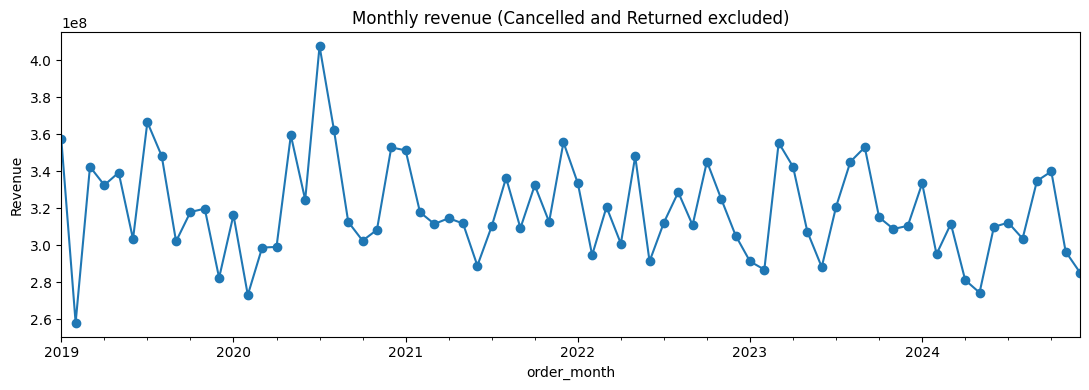

Insight: peak month is Jul 2020 at 407,508,620. Data runs Jan 2019 to Dec 2024; the last month may be partial, so compare full years.


In [40]:
kpi_sales = sales[sales["counts_for_kpi"]]

monthly = kpi_sales.groupby("order_month")["line_revenue"].sum()
fig, ax = plt.subplots(figsize=(11, 4))
monthly.plot(ax=ax, marker="o")
ax.set_title("Monthly revenue (Cancelled and Returned excluded)")
ax.set_ylabel("Revenue")
plt.tight_layout(); plt.show()
peak = monthly.idxmax()
print(f"Insight: peak month is {peak:%b %Y} at {monthly.max():,.0f}. "
      f"Data runs {monthly.index.min():%b %Y} to {monthly.index.max():%b %Y}; "
      f"the last month may be partial, so compare full years.")

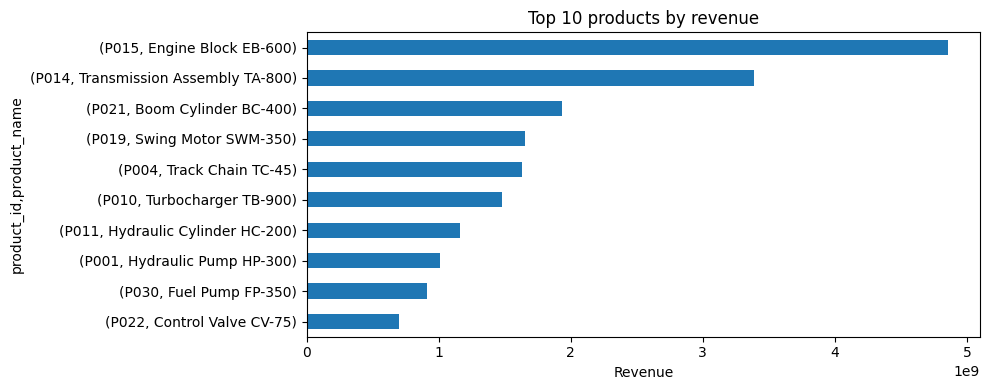

Insight: the top 10 products make up 81.5% of revenue; leader is Engine Block EB-600 at 21.2%.


In [41]:
top_products = (kpi_sales.groupby(["product_id", "product_name"])["line_revenue"].sum()
                .sort_values(ascending=False).head(10))
total_rev = kpi_sales["line_revenue"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
top_products.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 10 products by revenue")
ax.set_xlabel("Revenue")
plt.tight_layout(); plt.show()
print(f"Insight: the top 10 products make up {top_products.sum() / total_rev:.1%} of revenue; "
      f"leader is {top_products.index[0][1]} at {top_products.iloc[0] / total_rev:.1%}.")

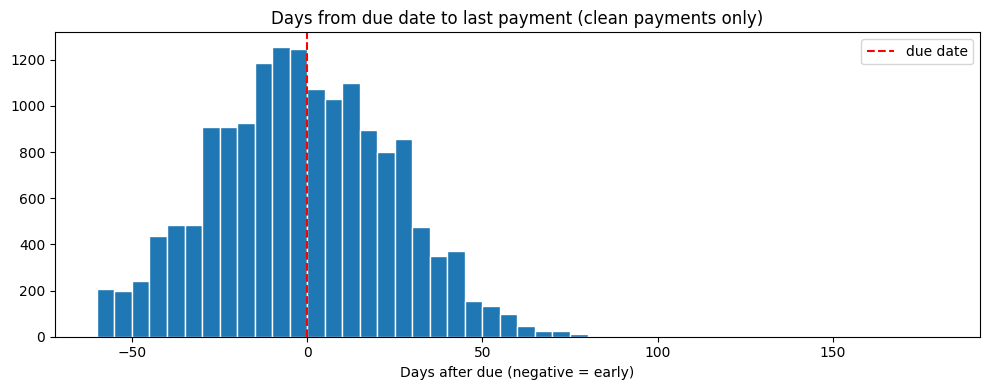

Insight: median payment is -2 days after due; 45.4% of clean payments are late.


In [42]:
paid = invoice_payment[invoice_payment["last_payment_date"].notna() & ~invoice_payment["payment_before_invoice"]
                       & (invoice_payment["days_paid_after_due"].abs() <= 365)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(paid["days_paid_after_due"], bins=range(-60, 181, 5), edgecolor="white")
ax.axvline(0, color="red", linestyle="--", label="due date")
ax.set_title("Days from due date to last payment (clean payments only)")
ax.set_xlabel("Days after due (negative = early)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Insight: median payment is {paid['days_paid_after_due'].median():.0f} days after due; "
      f"{(paid['days_paid_after_due'] > 0).mean():.1%} of clean payments are late.")

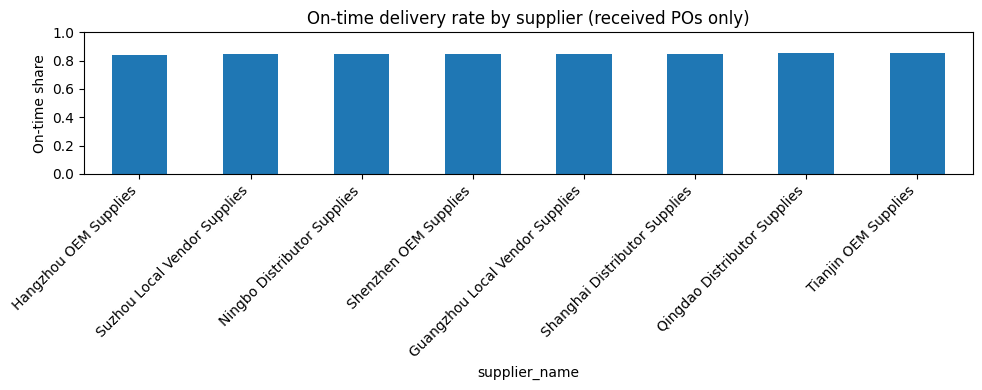

Insight: worst supplier is Hangzhou OEM Supplies at 84.2% on time (2,722 received POs); best is Tianjin OEM Supplies at 85.3%.


In [43]:
rec_po = po[po["is_on_time"].notna()].merge(tables["suppliers"][["supplier_id", "supplier_name"]],
                                           on="supplier_id", how="left")
by_supplier = (rec_po.groupby("supplier_name")["is_on_time"].agg(["mean", "size"])
               .rename(columns={"mean": "on_time_rate", "size": "received_pos"})
               .sort_values("on_time_rate"))
fig, ax = plt.subplots(figsize=(10, 4))
by_supplier["on_time_rate"].plot(kind="bar", ax=ax)
ax.set_title("On-time delivery rate by supplier (received POs only)")
ax.set_ylabel("On-time share"); ax.set_ylim(0, 1)
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
worst = by_supplier.index[0]
print(f"Insight: worst supplier is {worst} at {by_supplier.iloc[0]['on_time_rate']:.1%} on time "
      f"({int(by_supplier.iloc[0]['received_pos']):,} received POs); "
      f"best is {by_supplier.index[-1]} at {by_supplier.iloc[-1]['on_time_rate']:.1%}.")

## 9. KPI definitions and analysis questions
Week 1 target: 8 to 10 KPIs with formulas, and about 10 questions the team wants answered. The snapshot below computes the values from the cleaned data.

| # | KPI | Formula | Source table |
|---|---|---|---|
| 1 | Total revenue | sum of `line_total` where order status is not Cancelled or Returned | sales_lines + sales_orders |
| 2 | Gross margin % (approx.) | (revenue − sum of quantity × catalogue unit cost) ÷ revenue | sales features |
| 3 | Inventory value | sum of `current_stock × unit_cost` | inventory |
| 4 | Stockout rate | count of product-branch pairs with `current_stock` ≤ 0 ÷ all pairs | inventory |
| 5 | Inventory turnover | COGS ÷ average inventory value (opening and current stock) | sales features, inventory |
| 6 | Days of stock | `current_stock` ÷ average daily OUT quantity over the last 90 days | inventory, stock ledger |
| 7 | Supplier on-time delivery % | received POs with `received_date` ≤ `expected_delivery_date` ÷ received POs | purchase_orders |
| 8 | Average delivery delay (days) | mean of `received_date` − `expected_delivery_date`, received POs only | purchase_orders |
| 9 | Pending PO share | POs with no `received_date` ÷ all POs | purchase_orders |
| 10 | Invoice on-time payment % | invoices with last payment ≤ due date ÷ invoices with a clean payment | invoice_payment |

**Analysis questions for the team**
1. How has monthly revenue changed across full years, and which months are seasonal peaks?
2. Which 10 products drive most revenue, and do they match the products with the highest stock value?
3. What share of orders is cancelled or returned, by branch and by customer type?
4. Which branches hold the most stock value relative to their revenue?
5. Which product-branch pairs are at or below zero stock, and do they sell often?
6. Which suppliers deliver late most often, and by how many days on average?
7. How many purchase orders are still pending, and how old are they?
8. Which customer types pay late, and does payment terms explain it?
9. Does the stock ledger reconcile to current stock, and where does it not?
10. Which categories show the highest unit-price-to-cost markup?

In [44]:
s = kpi_sales
rec_po_all = po[po["is_on_time"].notna()]
paid_clean = invoice_payment[invoice_payment["last_payment_date"].notna() & ~invoice_payment["payment_before_invoice"]
                             & (invoice_payment["days_paid_after_due"].abs() <= 365)]

snapshot = {
    "1. Total revenue": f"{s['line_revenue'].sum():,.0f}",
    "2. Gross margin % (approx.)": f"{(s['line_revenue'].sum() - s['cogs_approx'].sum()) / s['line_revenue'].sum():.1%}",
    "3. Inventory value": f"{inv['stock_value'].sum():,.0f}",
    "4. Stockout rate": f"{(inv['current_stock'] <= 0).mean():.1%}",
    "7. Supplier on-time %": f"{rec_po_all['is_on_time'].astype(float).mean():.1%}",
    "8. Average delivery delay (days)": f"{rec_po_all['delivery_delay_days'].mean():.1f}",
    "9. Pending PO share": f"{(po['po_status'] == PENDING_PO_LABEL).mean():.1%}",
    "10. Invoice on-time payment %": f"{(paid_clean['days_paid_after_due'] <= 0).mean():.1%}",
}
pd.Series(snapshot, name="value").to_frame()

,value
1. Total revenue,"22,958,987,430"
2. Gross margin % (approx.),21.6%
3. Inventory value,"281,292,677,410"
4. Stockout rate,0.0%
7. Supplier on-time %,84.9%
8. Average delivery delay (days),0.5
9. Pending PO share,9.9%
10. Invoice on-time payment %,54.6%


## 10. Data dictionary (draft)
The structure below is generated from the data. The **description** column is blank on purpose: fill it from *Fields Documentation.docx* for all 12 tables before submitting.

In [45]:
rows = []
for name, df in raw.items():
    for c in df.columns:
        col = df[c]
        example = col.dropna().iloc[0] if col.notna().any() else ""
        rows.append({"table": name, "column": c, "dtype": str(col.dtype),
                     "null_%": round(100 * col.isna().mean(), 1),
                     "unique": int(col.nunique(dropna=True)),
                     "example": str(example),
                     "description": ""})
data_dictionary = pd.DataFrame(rows)
data_dictionary.to_csv(DOCS / "data_dictionary.csv", index=False)
print(f"Tables: {data_dictionary['table'].nunique()} | columns documented: {len(data_dictionary)} "
      f"| blank descriptions still to fill: {(data_dictionary['description'] == '').sum()}")
data_dictionary.head(15)

Tables: 12 | columns documented: 134 | blank descriptions still to fill: 134


,table,column,dtype,null_%,unique,example,description
0,branches,branch_id,object,0.0,6,DEL001,
1,branches,branch_name,object,0.0,6,Delhi Central,
2,branches,city,object,0.0,6,Delhi,
3,branches,state,object,0.0,6,Delhi,
4,branches,region,object,0.0,4,North,
5,branches,warehouse_type,object,0.0,4,Central,
6,branches,warehouse_capacity,object,0.0,6,45230 sqft,
7,branches,service_center_available,object,0.0,2,Yes,
8,branches,manager_id,int64,0.0,6,9593,
9,branches,total_employees,int64,0.0,6,92,


## 11. Validation log, cleaning log, and saved outputs

In [46]:
checks = [
    ("negative sales quantity", (sl["quantity"] < 0).sum(), len(sl), "fix or drop; none expected"),
    ("sales line_total != quantity x unit_price", mismatch.sum(), len(sl), "use line_total; review"),
    ("order delivered before order date", late_delivery.sum(), len(so), "flag; review"),
    ("received PO before order date", received_before_order.sum(), int(po["is_received"].sum()), "flag; exclude from delivery KPIs"),
    ("payment dated before invoice", n_before, len(invoice_payment), "flag; exclude from payment KPIs"),
    ("payment more than 365 days from due", int(extreme.sum()), len(invoice_payment), "flag; exclude from payment KPIs"),
    ("individual payment before its invoice", payment_rows_before, len(pay), "flag; check matching"),
    ("negative current stock", inv["negative_stock"].sum(), len(inv), "flag; check receipts"),
    ("duplicate product-branch in inventory", int(inv.duplicated(["product_id", "branch_id"]).sum()), len(inv), "must be 0"),
    ("stock does not reconcile to ledger", len(not_reconciled), len(recon), "flag; investigate"),
    ("ledger movement_type not IN/OUT", unknown_types, len(ledger), "exclude from reconciliation"),
    ("orphan keys across all relations", int(relationships["orphan_rows"].sum()), int(relationships["rows_checked"].sum()), "must be 0"),
]
validation = pd.DataFrame(checks, columns=["check", "rows_failed", "rows_total", "decision"])
validation["pct_failed"] = (100 * validation["rows_failed"] / validation["rows_total"]).round(2)
validation.to_csv(DOCS / "validation_log.csv", index=False)
pd.DataFrame(cleaning_log).to_csv(DOCS / "cleaning_log.csv", index=False)
validation

,check,rows_failed,rows_total,decision,pct_failed
0,negative sales quantity,0,130402,fix or drop; none expected,0.00
1,sales line_total != quantity x unit_price,0,130402,use line_total; review,0.00
2,order delivered before order date,0,20000,flag; review,0.00
3,received PO before order date,0,21630,flag; exclude from delivery KPIs,0.00
4,payment dated before invoice,10,17836,flag; exclude from payment KPIs,0.06
5,payment more than 365 days from due,76,17836,flag; exclude from payment KPIs,0.43
6,individual payment before its invoice,92,19257,flag; check matching,0.48
7,negative current stock,0,180,flag; check receipts,0.00
8,duplicate product-branch in inventory,0,180,must be 0,0.00
9,stock does not reconcile to ledger,179,180,flag; investigate,99.44


In [47]:
for name, df in tables.items():
    df.to_csv(CLEAN / f"{name}_clean.csv", index=False)
sales.to_csv(CLEAN / "sales_features.csv", index=False)
purchase.to_csv(CLEAN / "purchase_features.csv", index=False)
inv.to_csv(CLEAN / "inventory_features.csv", index=False)
invoice_payment.to_csv(CLEAN / "invoice_payment_features.csv", index=False)

print("Saved to", CLEAN.resolve())
print(f"Completeness across the 12 raw tables: "
      f"{1 - summary['null_cells'].sum() / sum(df.size for df in raw.values()):.2%} of cells non-null "
      f"(the gap is mostly the {int(po['is_received'].eq(False).sum()):,} pending POs)")
print("Date range, sales orders:", so["order_date"].min().date(), "to", so["order_date"].max().date())

Saved to /content/data/cleaned
Completeness across the 12 raw tables: 99.96% of cells non-null (the gap is mostly the 2,370 pending POs)
Date range, sales orders: 2019-01-01 to 2024-12-31


## 12. Week 1 checklist (computed)
Run this last. Each line is calculated from this run, so it cannot drift from the data.

In [48]:
checklist = {
    "All 12 tables loaded": len(tables) == 12,
    "Primary keys unique (after cleaning)": bool((pk_check["pk_duplicates"] == 0).all()),
    "Relationships checked": len(relationships) >= 12,
    "Orphan keys": int(relationships["orphan_rows"].sum()),
    "Inventory reconciles to ledger (pairs)": f"{len(recon) - len(not_reconciled)} of {len(recon)}",
    "Validation checks flagged": int((validation["rows_failed"] > 0).sum()),
    "Cleaning actions logged": len(cleaning_log),
    "Data dictionary descriptions still blank": int((data_dictionary["description"] == "").sum()),
}
for k, v in checklist.items():
    print(f"{k:45s} {v}")

All 12 tables loaded                          True
Primary keys unique (after cleaning)          False
Relationships checked                         True
Orphan keys                                   0
Inventory reconciles to ledger (pairs)        1 of 180
Validation checks flagged                     5
Cleaning actions logged                       11
Data dictionary descriptions still blank      134
